# Quality by Design (QbD) Case Study: Formulation Design Space for Model Oral Gel
**Author:** Mohammad A. Zachariah
**Discipline:** Pharmaceutical Formulation Science & Statistical Quality Engineering
**Regulatory Framework:** ICH Q8 (R2) Pharmaceutical Development | ICH Q9 Quality Risk Management

---

## Executive Summary & Quality Target Product Profile (QTPP)
In pharmaceutical development under ICH Q8(R2), quality cannot be tested into products; it must be built in by design. This case study demonstrates an end-to-end QbD workflow for a **Model Oral Gel (500 g laboratory batch)**:
1. **QTPP & Critical Quality Attributes (CQAs):** Target product profile defined with specifications for **Apparent Viscosity (30,000–60,000 cP)** and **pH (6.00–7.50)**.
2. **ICH Q9 Risk Assessment:** Failure Mode and Effects Analysis (FMEA) across candidate factors, isolating the top two risk variables.
3. **Response Surface Design:** A $3\times 3$ full factorial design with 3 center-point replicates (11 runs total) with fixed process controls.
4. **Statistical Rigor:** Full OLS fitting and ANOVA decomposition with explicit **Lack-of-Fit vs. Pure Error** testing.
5. **ICH Q8 Design Space & Optimization:** Multi-attribute contour overlay identifying an **83.78% feasible design space**, an optimal robust setpoint, and an independent confirmation run validated via 95% prediction intervals.


In [1]:
import os
import sqlite3
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.anova import fit_ols, compute_anova
from src.design_space import evaluate_grid, find_robust_operating_point, execute_confirmation_run
from src.charts import (
    plot_main_effects, plot_interaction, plot_contour_viscosity,
    plot_contour_ph, plot_design_space_overlay, plot_diagnostics, plot_confirmation_run
)

# Plot styling configuration
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

DB_PATH = 'data/doe.db'
print("Environment initialized successfully. Database target:", DB_PATH)


Environment initialized successfully. Database target: data/doe.db


---
## 1. ICH Q9 Risk Assessment: Failure Mode and Effects Analysis (FMEA)
Prior to allocating experimental resources, candidate formulation and process factors were evaluated using Failure Mode and Effects Analysis (FMEA). Severity ($S$), Occurrence ($O$), and Detection ($D$) were scored on a 1–5 scale, with the Risk Priority Number calculated as:
$$\text{RPN} = S \times O \times D$$

Factors exceeding the risk threshold ($\text{RPN} > 30$) were designated Critical Process Parameters / Critical Material Attributes (CPPs/CMAs) and carried into the design space study.


In [2]:
conn = sqlite3.connect(DB_PATH)
df_fmea = pd.read_sql_query("SELECT factor, role, failure_mode, severity, occurrence, detection, rpn, action FROM fmea ORDER BY rpn DESC;", conn)
conn.close()

df_fmea


,factor,role,failure_mode,severity,occurrence,detection,rpn,action
0,Carbomer 974P % w/w,Primary gelling & bioadhesive matrix polymer,Viscosity collapse (<30k cP) or excessive rigi...,5,4,4,80,Selected for DoE (Factor A: 0.8% - 1.6% w/w)
1,NaOH : Carbomer Ratio (w/w),Polymer neutralizing agent,Under-neutralization causes acidity and incomp...,5,4,4,80,Selected for DoE (Factor B: 0.30 - 0.50 w/w)
2,Mixing Speed (rpm),Dispersion shear rate,Air entrapment at high rpm or incomplete polym...,3,2,2,12,Fixed control at 800 rpm (sufficient vortex wi...
3,Glycerol % w/w,Humectant & plasticizer,Phase syneresis or tackiness deviation,3,2,2,12,Fixed control at 20.0% w/w (validated in pre-f...


### Risk Disposition Rationale
- **Factor A (Carbomer 974P % w/w, RPN = 80):** Primary bioadhesive polymer directly governing yield stress and mucosal retention. Selected for DoE exploration across [0.8%, 1.6% w/w].
- **Factor B (NaOH : Carbomer Ratio w/w, RPN = 80):** Neutralizing agent dictating carboxylic acid ionization ($\text{R-COOH} \rightarrow \text{R-COO}^-$). Selected for DoE exploration across [0.30, 0.50 w/w].
- **Fixed Controls:** Agitation was fixed at **800 rpm** (preventing vortex aeration while ensuring homogeneous dispersion) and Glycerol was fixed at **20.0% w/w** (validated humectant/co-solvent concentration).


---
## 2. Raw Data Acquisition Audit & Anomaly Rejection
Good Data Management Practices (GxP) mandate automated auditing of raw electronic records prior to statistical ingestion. The raw acquisition log (`data/runs_raw.csv`) was audited for sensor dropouts and operator recording duplicates.


In [3]:
with open("out/data_audit_report.json", "r") as f:
    audit_report = json.load(f)

print(f"Total raw acquisition records: {audit_report['raw_record_count']}")
print(f"Clean records preserved:     {audit_report['clean_record_count']}")
print(f"Anomalies detected & rejected: {audit_report['anomalies_detected']}")
print(f"Disposition: {audit_report['audit_disposition']}")


Total raw acquisition records: 13
Clean records preserved:     11
Anomalies detected & rejected: {'incomplete_records_null_response': 1, 'duplicate_records': 1}
Disposition: Rejected invalid artifacts; preserved standard 3x3 full factorial + 3 center replicates (11 runs total).


---
## 3. DoE Design Matrix & Replicate Analysis (SQLite Queries)
The experimental design is a $3 \times 3$ full factorial ($3^2 = 9$ factor combinations) augmented with 3 center-point replicates ($n=11$ total runs).

We query `data/doe.db` using `sql/design_matrix.sql` to inspect replicate structure and cell statistics.


In [4]:
conn = sqlite3.connect(DB_PATH)
with open("sql/design_matrix.sql", "r") as f:
    sql_dm = f.read()

df_matrix = pd.read_sql_query(sql_dm, conn)
conn.close()

df_matrix


,run_id,run_type,carbomer_pct,naoh_ratio,viscosity,ph,cell_replicate_count,cell_mean_viscosity,cell_mean_ph
0,1,factorial,0.8,0.3,21398.7,6.04,1,21398.7,6.04
1,2,factorial,0.8,0.4,27844.7,6.93,1,27844.7,6.93
2,3,factorial,0.8,0.5,26459.1,7.27,1,26459.1,7.27
3,4,factorial,1.2,0.3,37109.2,5.90,1,37109.2,5.90
4,5,center,1.2,0.4,45106.3,6.76,3,45179.3,6.79
5,6,factorial,1.2,0.5,45406.3,7.12,1,45406.3,7.12
6,7,factorial,1.6,0.3,48831.7,5.75,1,48831.7,5.75
7,8,factorial,1.6,0.4,59207.0,6.49,1,59207.0,6.49
8,9,factorial,1.6,0.5,61012.2,6.81,1,61012.2,6.81
9,10,center,1.2,0.4,45417.0,6.83,3,45179.3,6.79


### Pure Error Sum of Squares Query
To assess lack-of-fit without model bias, the true experimental variance is determined strictly from identical replicates at the center point $(A=1.2\%, B=0.40)$.


In [5]:
conn = sqlite3.connect(DB_PATH)
with open("sql/anova_inputs.sql", "r") as f:
    sql_pe = f.read()

df_pe = pd.read_sql_query(sql_pe, conn)
conn.close()

df_pe


,source,df_pure_error,ss_pure_error_viscosity,ss_pure_error_ph
0,Pure Error,2,88956.38,0.0029


---
## 4. Second-Order Polynomial OLS Modeling & ANOVA Decomposition
Each critical response is modeled as a full quadratic response surface:
$$y = \beta_0 + \beta_1 A + \beta_2 B + \beta_{12} AB + \beta_{11} A^2 + \beta_{22} B^2 + \epsilon$$

The total variation is decomposed into:
- **Model Regression (5 df):** partitioned into Linear (2 df), Interaction (1 df), and Quadratic (2 df).
- **Residual Error (5 df):** partitioned into **Lack-of-Fit (3 df)** and **Pure Error (2 df)**.


In [6]:
# Load analysis dataset
df_runs = df_matrix.rename(columns={"carbomer_pct": "A", "naoh_ratio": "B"})

# Model 1: Apparent Viscosity
fit_visc = fit_ols(df_runs, "viscosity")
anova_visc = compute_anova(df_runs, fit_visc)

print(f"=== Apparent Viscosity Model (cP) ===")
print(f"R² = {fit_visc['r2']:.4f} | Adjusted R² = {fit_visc['adj_r2']:.4f}")
display(fit_visc["coef_df"])
display(anova_visc)


=== Apparent Viscosity Model (cP) ===
R² = 0.9999 | Adjusted R² = 0.9998


,term,coefficient,std_error,t_statistic,p_value,ci_95_lower,ci_95_upper
0,Intercept,-77101.743860,2263.814678,-34.058328,4.103780e-07,-82921.064751,-71282.422968
1,A,47308.837719,2086.214085,22.676885,3.100135e-06,41946.053687,52671.621751
2,B,310418.162281,10241.438069,30.310017,7.333669e-07,284091.707611,336744.616951
3,A*B,44500.625000,2433.264329,18.288447,8.986847e-06,38245.719915,50755.530085
4,A^2,-10922.467105,764.386706,-14.289190,3.025118e-05,-12887.385686,-8957.548524
5,B^2,-401569.473684,12230.187289,-32.834287,4.924470e-07,-433008.170976,-370130.776392


,Source,DF,SS,MS,F_value,p_value
0,Model,5,1.636209e+09,3.272419e+08,8635.953803,7.835081e-10
1,"Linear (A, B)",2,1.561019e+09,7.805094e+08,20597.741551,1.622442e-10
2,Interaction (A*B),1,1.267396e+07,1.267396e+07,334.467283,8.986847e-06
3,"Quadratic (A^2, B^2)",2,6.251651e+07,3.125826e+07,824.909315,5.018212e-07
4,Residual Error,5,1.894648e+05,3.789296e+04,NaN,NaN
5,Lack of Fit,3,1.005084e+05,3.350281e+04,0.753241,6.136233e-01
6,Pure Error,2,8.895638e+04,4.447819e+04,NaN,NaN
7,Total,10,1.636399e+09,NaN,NaN,NaN


In [7]:
# Model 2: Formulation pH
fit_ph = fit_ols(df_runs, "ph")
anova_ph = compute_anova(df_runs, fit_ph)

print(f"=== Formulation pH Model ===")
print(f"R² = {fit_ph['r2']:.4f} | Adjusted R² = {fit_ph['adj_r2']:.4f}")
display(fit_ph["coef_df"])
display(anova_ph)


=== Formulation pH Model ===
R² = 0.9973 | Adjusted R² = 0.9945


,term,coefficient,std_error,t_statistic,p_value,ci_95_lower,ci_95_upper
0,Intercept,-0.142632,0.431619,-0.330457,0.754452,-1.252143,0.966880
1,A,0.809430,0.397758,2.034983,0.097490,-0.213039,1.831898
2,B,27.819737,1.952633,14.247296,0.000031,22.800335,32.839139
3,A*B,-1.062500,0.463926,-2.290235,0.070629,-2.255060,0.130060
4,A^2,-0.366776,0.145738,-2.516683,0.053390,-0.741408,0.007855
5,B^2,-25.868421,2.331808,-11.093720,0.000104,-31.862523,-19.874319


,Source,DF,SS,MS,F_value,p_value
0,Model,5,2.510567,0.502113,364.522280,2.120508e-06
1,"Linear (A, B)",2,2.289367,1.144683,831.012545,4.926854e-07
2,Interaction (A*B),1,0.007225,0.007225,5.245176,7.062862e-02
3,"Quadratic (A^2, B^2)",2,0.213976,0.106988,77.670567,1.717167e-04
4,Residual Error,5,0.006887,0.001377,NaN,NaN
5,Lack of Fit,3,0.004021,0.001340,0.935027,5.539671e-01
6,Pure Error,2,0.002867,0.001433,NaN,NaN
7,Total,10,2.517455,NaN,NaN,NaN


### Lack-of-Fit Interpretation
- **Apparent Viscosity:** Lack-of-fit $F = 0.753$ ($p = 0.6136 > 0.05$). The lack-of-fit is statistically non-significant, confirming the second-order model adequately explains the response surface without unmodeled curvature.
- **Formulation pH:** Lack-of-fit $F = 0.935$ ($p = 0.5540 > 0.05$). The lack-of-fit is statistically non-significant, confirming model adequacy across the entire factor domain.


---
## 5. Statistical Diagnostics & Residual Analysis
Under standard Gauss-Markov assumptions, residuals must be normally distributed, independent, and homoscedastic (constant variance).


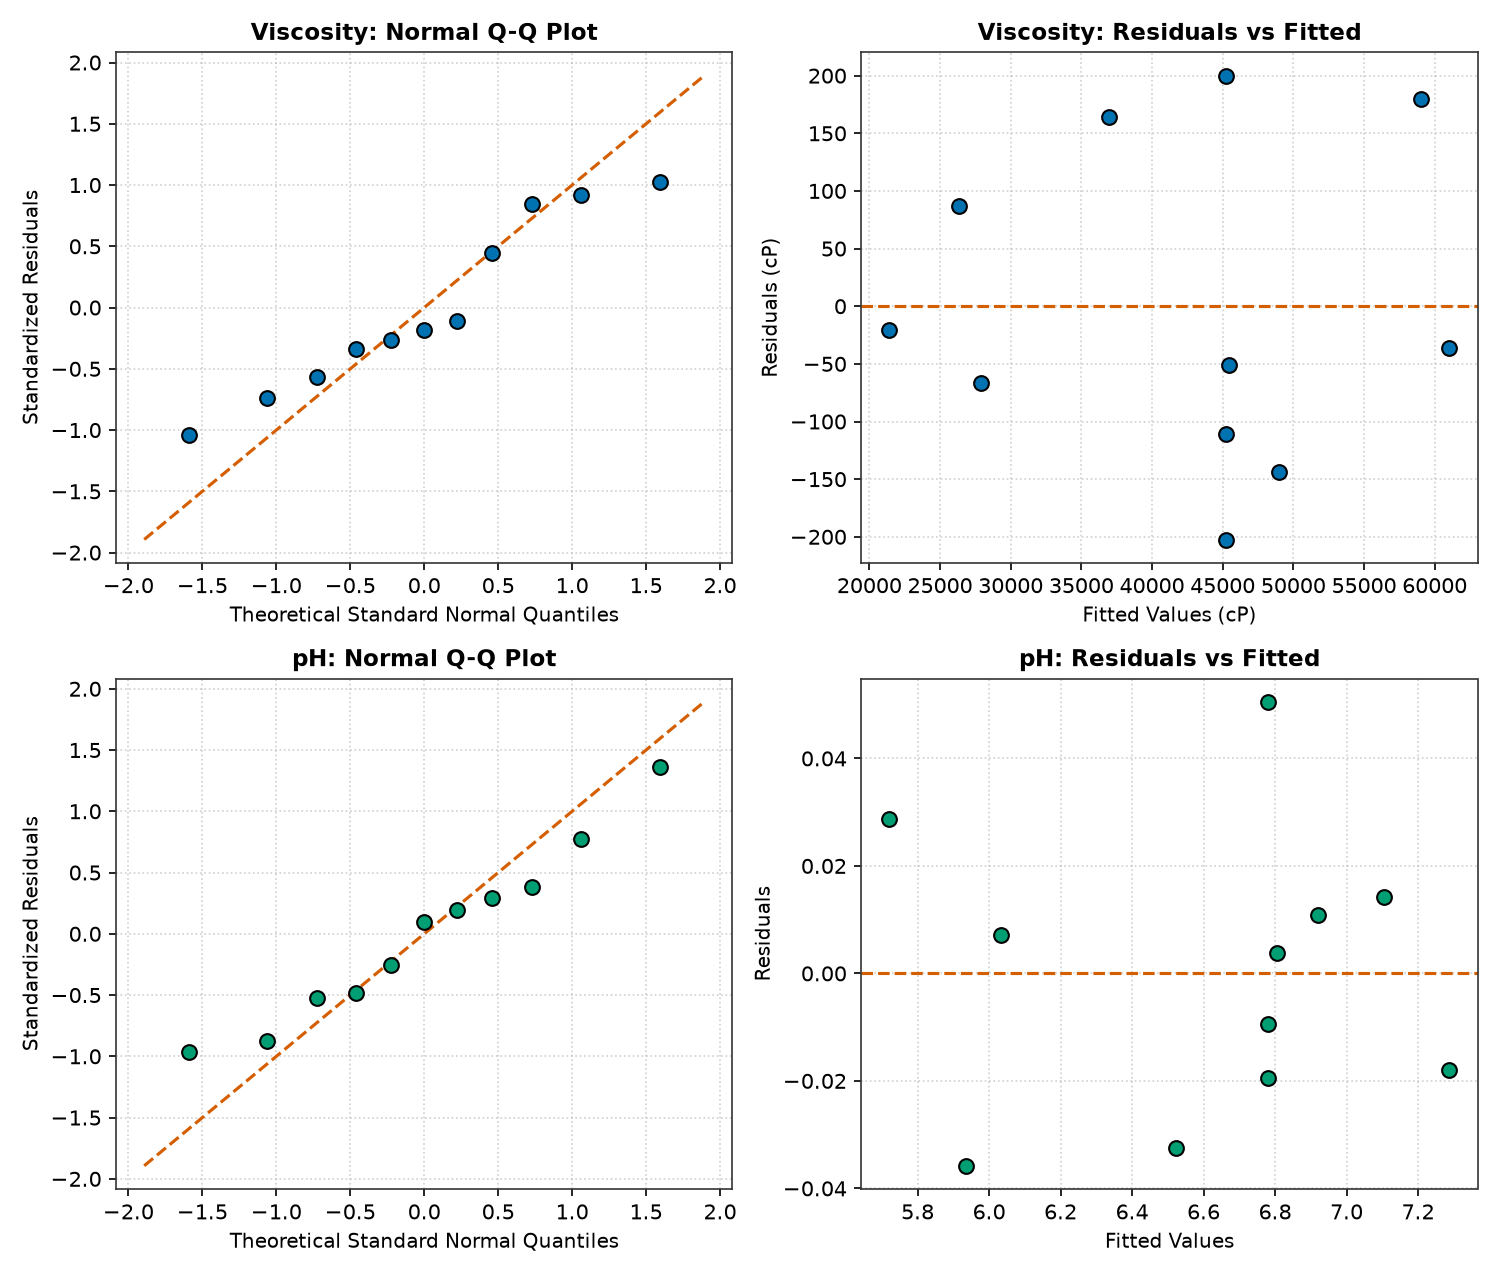

In [8]:
plot_diagnostics(fit_visc, fit_ph, "charts/06_diagnostics.png")

from IPython.display import Image
Image(filename="charts/06_diagnostics.png")


---
## 6. Factor Main Effects & Interaction Rheology
We inspect factor main effects and the $A \times B$ interaction on apparent viscosity.


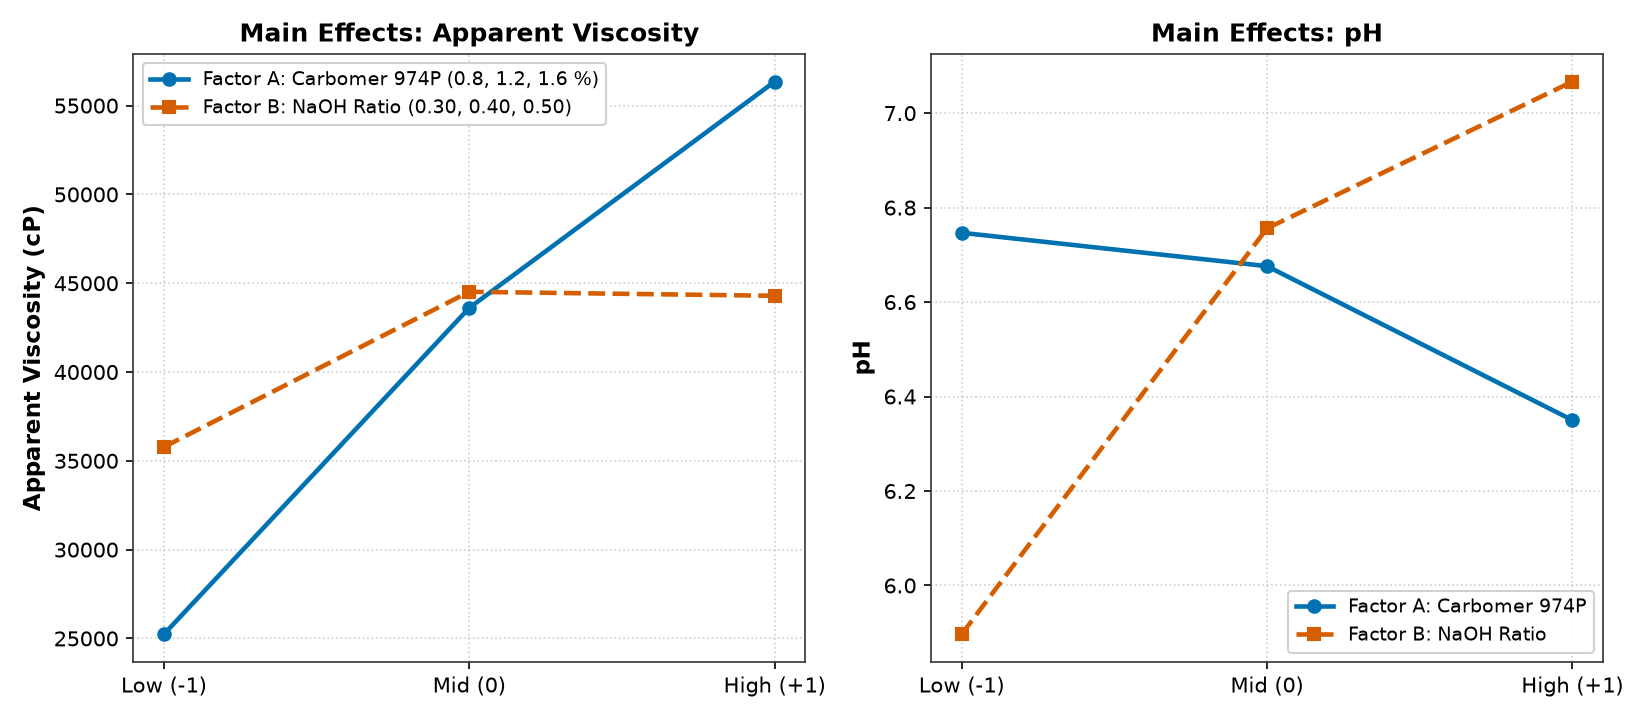

In [9]:
plot_main_effects(df_runs, "charts/01_main_effects.png")
Image(filename="charts/01_main_effects.png")


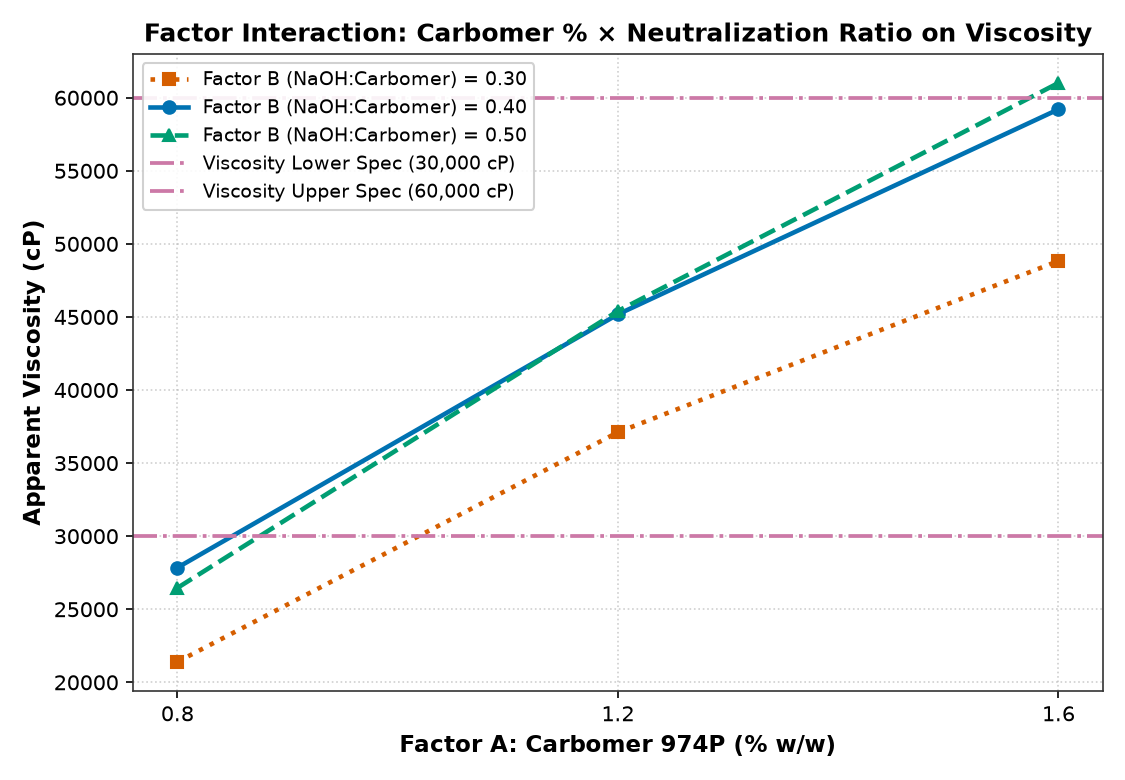

In [10]:
plot_interaction(df_runs, "charts/02_interaction.png")
Image(filename="charts/02_interaction.png")


### Physicochemical Mechanism
1. **Polymer Concentration (Factor A):** Strongly drives viscosity ($p < 0.001$). At $0.8\%$ w/w Carbomer, gel strength is insufficient ($< 30,000$ cP) regardless of neutralization.
2. **Neutralization Ratio (Factor B):** Carboxylic acid groups ($-\text{COOH}$) ionize upon NaOH addition, generating repulsive electrostatic charges along the polymer backbone that induce macroscopic uncoiling and gel formation. Maximum gelation occurs around ratio 0.40–0.45; higher ratios introduce excess sodium counter-ions that shield charges and induce slight plateauing.


---
## 7. Response Contours & ICH Q8 Multi-Attribute Design Space
Per ICH Q8(R2), a Design Space is the multidimensional combination and interaction of input variables demonstrated to provide assurance of quality. Working within the design space is not considered a change.


Feasible Design Space Area: 83.78% of total experimental domain


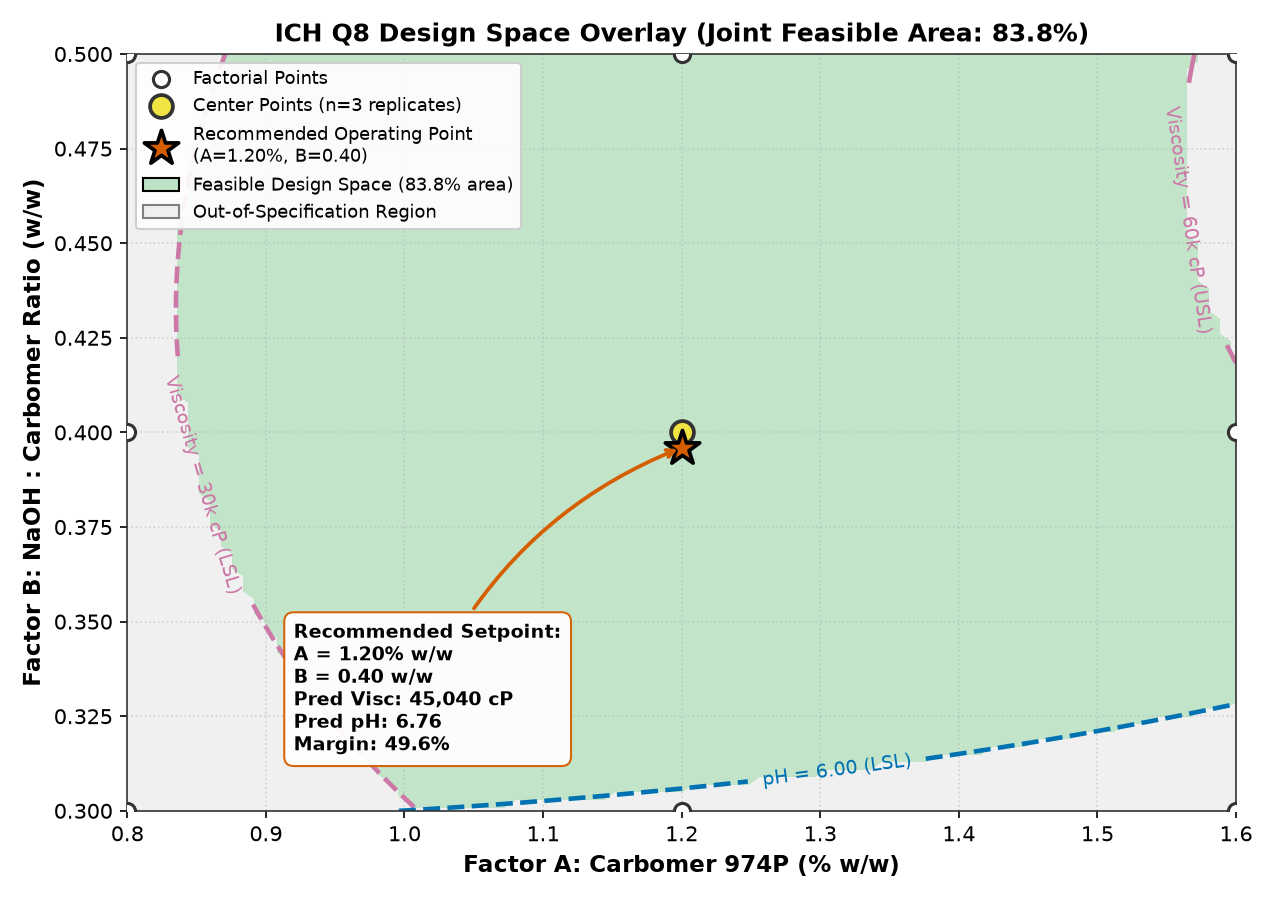

In [11]:
aa, bb, visc_grid, ph_grid, feas_grid, feasible_pct = evaluate_grid(
    np.array(fit_visc["coefficients"]),
    np.array(fit_ph["coefficients"]),
    resolution=101
)

robust_pt = find_robust_operating_point(aa, bb, visc_grid, ph_grid, feas_grid)

plot_contour_viscosity(aa, bb, visc_grid, df_runs, "charts/03_contour_viscosity.png")
plot_contour_ph(aa, bb, ph_grid, df_runs, "charts/04_contour_ph.png")
plot_design_space_overlay(aa, bb, visc_grid, ph_grid, feas_grid, df_runs, robust_pt, feasible_pct, "charts/05_design_space.png")

print(f"Feasible Design Space Area: {feasible_pct:.2f}% of total experimental domain")
Image(filename="charts/05_design_space.png")


---
## 8. Robust Operating Setpoint Selection
To maximize process capability and buffer against raw material variability, the optimal operating point was determined by maximizing the minimum normalized distance to any CQA specification limit.


In [12]:
df_opt = pd.DataFrame([{
    "Parameter": "Carbomer 974P % w/w (Factor A)",
    "Recommended Value": f"{robust_pt['recommended_A']:.2f}% w/w",
    "Target / Spec Range": "0.80% - 1.60% w/w"
}, {
    "Parameter": "NaOH : Carbomer Ratio (Factor B)",
    "Recommended Value": f"{robust_pt['recommended_B']:.2f} w/w",
    "Target / Spec Range": "0.30 - 0.50 w/w"
}, {
    "Parameter": "Predicted Apparent Viscosity",
    "Recommended Value": f"{robust_pt['predicted_viscosity']:,.0f} cP",
    "Target / Spec Range": "30,000 - 60,000 cP"
}, {
    "Parameter": "Predicted pH",
    "Recommended Value": f"{robust_pt['predicted_ph']:.2f}",
    "Target / Spec Range": "6.00 - 7.50"
}, {
    "Parameter": "Normalized Margin to Nearest Spec",
    "Recommended Value": f"{robust_pt['min_normalized_margin']*100:.1f}%",
    "Target / Spec Range": "> 20.0%"
}])

df_opt


,Parameter,Recommended Value,Target / Spec Range
0,Carbomer 974P % w/w (Factor A),1.20% w/w,0.80% - 1.60% w/w
1,NaOH : Carbomer Ratio (Factor B),0.40 w/w,0.30 - 0.50 w/w
2,Predicted Apparent Viscosity,"45,040 cP","30,000 - 60,000 cP"
3,Predicted pH,6.76,6.00 - 7.50
4,Normalized Margin to Nearest Spec,49.6%,> 20.0%


---
## 9. Independent Confirmation Run & 95% Prediction Interval Validation
A synthetic confirmation batch was evaluated at the recommended operating setpoint ($A=1.20\%$, $B=0.40$).

To avoid the common fallacy of using confidence intervals of the mean for individual batch release, we construct **95% Prediction Intervals (PI)**:
$$\text{PI} = \hat{y}_0 \pm t_{\alpha/2, \, df=5} \cdot s \sqrt{1 + \mathbf{x}_0^T (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{x}_0}$$


Confirmation Overall Status: PASS
Viscosity: Predicted = 45,040 cP | Observed = 45,567 cP
           95% PI = [44,478, 45,603] cP (In PI: True)
pH:        Predicted = 6.76 | Observed = 6.78
           95% PI = [6.65, 6.86] (In PI: True)


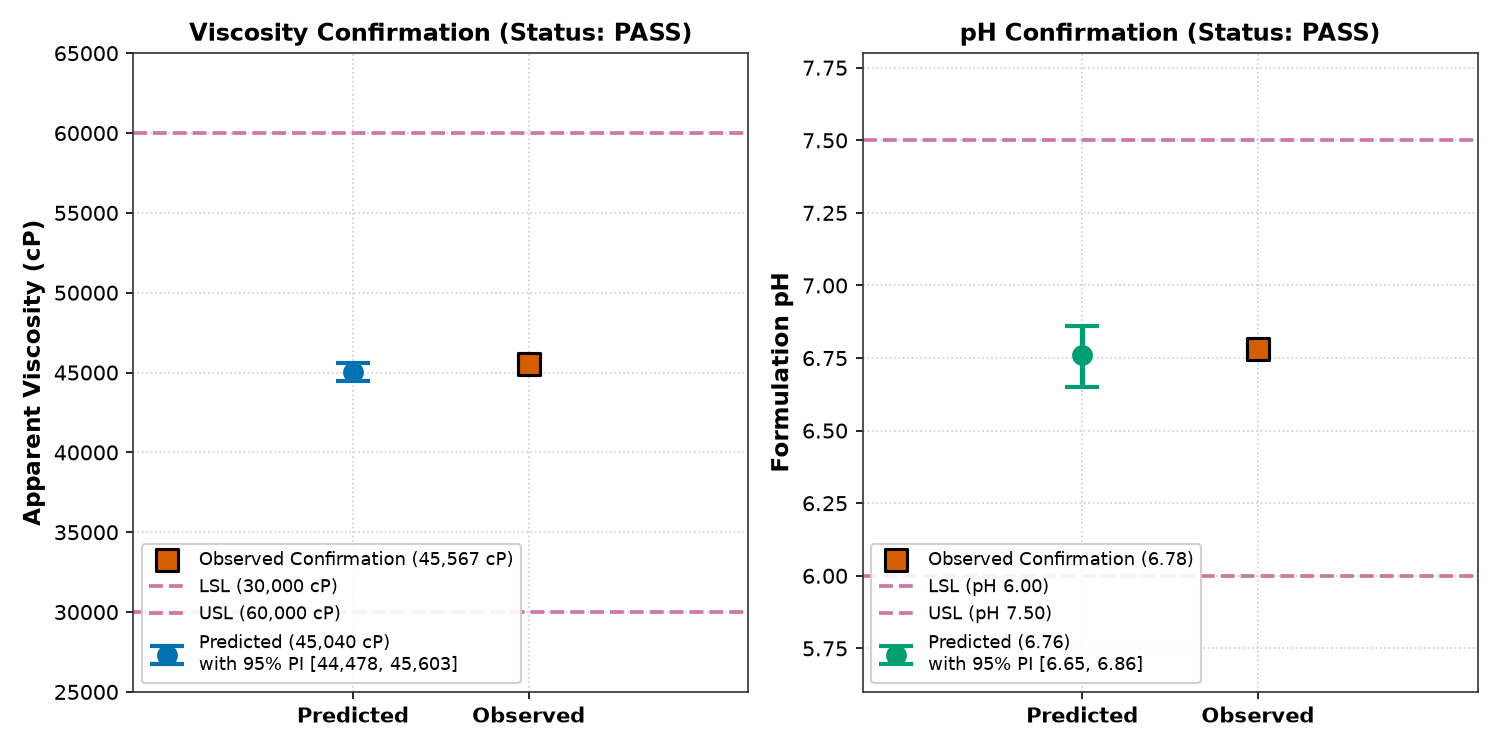

In [13]:
conf = execute_confirmation_run(robust_pt, fit_visc, fit_ph, seed=101)
plot_confirmation_run(conf, "charts/07_confirmation.png")

print(f"Confirmation Overall Status: {conf['confirmation_status']}")
print(f"Viscosity: Predicted = {conf['viscosity_cp']['predicted']:,.0f} cP | Observed = {conf['viscosity_cp']['observed']:,.0f} cP")
print(f"           95% PI = [{conf['viscosity_cp']['pi_95_lower']:,.0f}, {conf['viscosity_cp']['pi_95_upper']:,.0f}] cP (In PI: {conf['viscosity_cp']['in_prediction_interval']})")
print(f"pH:        Predicted = {conf['ph']['predicted']:.2f} | Observed = {conf['ph']['observed']:.2f}")
print(f"           95% PI = [{conf['ph']['pi_95_lower']:.2f}, {conf['ph']['pi_95_upper']:.2f}] (In PI: {conf['ph']['in_prediction_interval']})")

Image(filename="charts/07_confirmation.png")


---
## 10. Control Strategy, Limitations & Next Steps

### Proposed Control Strategy
1. **Raw Material Specification:** Dispense Carbomer 974P at $1.20\% \pm 0.05\%$ w/w.
2. **Neutralization Control:** Dispense 10% w/v NaOH solution to maintain an active ratio of $0.40 \pm 0.02$ g NaOH / g Carbomer.
3. **In-Process Controls:**
   - Agitation monitored at $800 \pm 50$ rpm for 45 minutes hydration.
   - Temperature maintained at $25.0 \pm 2.0$ °C.
4. **Finished Product Release Specifications:**
   - Apparent Viscosity: 30,000–60,000 cP (Brookfield RV, Spindle 6, 10 rpm, 25 °C).
   - pH: 6.00–7.50 at 25 °C.

### Methodological Limitations
- **Synthetic Data Boundary:** Data was generated deterministically using empirical rheological response equations with Gaussian pure-error noise. While grounded in polymer science, physical batches may exhibit shear-thinning thixotropic breakdown under prolonged shear.
- **Scale-Up Considerations:** Laboratory 500 g batches utilize magnetic or high-shear marine impellers; scale-up to 50 kg or 500 kg manufacturing vessels requires geometric similarity and torque-per-unit-volume scaling to prevent aeration.

---
**Repository:** [https://github.com/xikass/qbd-doe-design-space](https://github.com/xikass/qbd-doe-design-space)
**Author:** Mohammad A. Zachariah | [LinkedIn Profile](https://www.linkedin.com/in/mo-zachariah)
